# Tweet Topic Multi-Label Classification — Evaluation & Deep Error Analysis (`S0 → S4`)

**Người thực hiện:** Nguyễn Văn Sơn  
**Backbone:** `bert-base-uncased` (110M parameters) | **Dataset:** [`cardiffnlp/tweet_topic_multi`](https://huggingface.co/datasets/cardiffnlp/tweet_topic_multi) (`19` topics, Temporal Split `2020 → 2021`)  
**Cấu hình huấn luyện (100% Kaggle GPU):** `10 Epochs + Cosine Annealing + Early Stopping (patience = 3)` (`configs/v4/v4_s0..s4*.yaml`)

> **Phạm vi thực thi của Notebook (Pure-CPU Post-Hoc Evaluation):**  
> Notebook này **không huấn luyện mô hình** — toàn bộ số liệu, bảng đối chiếu và phân tích lỗi được tính toán lại trực tiếp từ các tệp đầu ra đã huấn luyện trên Kaggle GPU (`outputs/v4_*/metrics_summary.json`, `test_predictions.json`, `val_probabilities.json`) nhằm bảo đảm **100% truy xuất nguồn gốc (code traceability)** cho báo cáo kỹ thuật (`docs/technical_report.md`) và bộ slide thuyết trình (`presentation/tweet_topic_bert_evaluation.pptx`).

### Mục lục Truy xuất Nhanh
1. **Master Benchmark Table (`S0 → S4`, `TF-IDF`, `COLING 2022`) & 3-Seed Stability**
2. **Per-Class Recovery (19 Chủ đề) & Strict Substitution Matrix (`S1 → S4`)**
3. **Full Audit `918 / 1,679` Failed Samples (`1,474` Binary Errors) & Exact Match Recovery**
4. **Core Error Mechanisms inside `S4`: Co-occurrence Halo, `{@Entity@}` Shortcut & Secondary-Label Suppression**
5. **Calibration Trade-off (`ECE` & Overconfidence Gap), 2021 Drift (`news` Recall) & Selective Prediction (`80% Auto`)**
6. **Qualitative Case Study Inspector (`Idx 608`, `Idx 993`, `Idx 1145`, `Idx 8` & Win Cases)**
7. **Zero-Leakage `validation_2020` Root-Cause Diagnosis (`test_splits_accessed = []`)**

In [1]:
import json
import re
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import load_dataset
from sklearn.metrics import f1_score

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 110)

# Resolve repository root cleanly regardless of current working directory
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "analysis" else Path.cwd()
OUT_ROOT = REPO_ROOT / "outputs"
assert (OUT_ROOT / "v4_s4_damped_wbce" / "test_predictions.json").exists(), f"Missing Kaggle outputs under {OUT_ROOT}"

LABELS = [
    "arts_&_culture", "business_&_entrepreneurs", "celebrity_&_pop_culture",
    "diaries_&_daily_life", "family", "fashion_&_style", "film_tv_&_video",
    "fitness_&_health", "food_&_dining", "gaming", "learning_&_educational",
    "music", "news_&_social_concern", "other_hobbies", "relationships",
    "science_&_technology", "sports", "travel_&_adventure", "youth_&_student_life",
]
SHORT = {
    "arts_&_culture": "arts", "business_&_entrepreneurs": "business",
    "celebrity_&_pop_culture": "celebrity", "diaries_&_daily_life": "diaries",
    "family": "family", "fashion_&_style": "fashion", "film_tv_&_video": "film_tv",
    "fitness_&_health": "fitness", "food_&_dining": "food", "gaming": "gaming",
    "learning_&_educational": "learning", "music": "music",
    "news_&_social_concern": "news", "other_hobbies": "hobbies",
    "relationships": "relationships", "science_&_technology": "science",
    "sports": "sports", "travel_&_adventure": "travel", "youth_&_student_life": "youth",
}
IDX = {lbl: i for i, lbl in enumerate(LABELS)}

STAGES = [
    ("S0", "v4_s0_stock_bce"),
    ("S1", "v4_s1_custom_head_bce"),
    ("S2", "v4_s2_cleaner_bce"),
    ("S3", "v4_s3_hybrid_pool_msd_bce"),
    ("S4", "v4_s4_damped_wbce"),
]

def load_run(run_dir_name: str):
    d = OUT_ROOT / run_dir_name
    ms = json.loads((d / "metrics_summary.json").read_text(encoding="utf-8"))
    tp = json.loads((d / "test_predictions.json").read_text(encoding="utf-8"))
    vp_path = d / "val_probabilities.json"
    vp = json.loads(vp_path.read_text(encoding="utf-8")) if vp_path.exists() else None
    hist_path = d / "training_history.json"
    hist = json.loads(hist_path.read_text(encoding="utf-8")) if hist_path.exists() else None
    return ms, tp, vp, hist

# Load HuggingFace text splits (cached locally; zero model weights loaded)
ds = load_dataset("cardiffnlp/tweet_topic_multi")
texts_train = ds["train_2020"]["text"]
texts_val = ds["validation_2020"]["text"]
texts_2020 = ds["test_2020"]["text"]
texts_2021 = ds["test_2021"]["text"]

runs = {tag: load_run(folder) for tag, folder in STAGES}
s4_ms, s4_tp, s4_vp, _ = runs["S4"]
y_true_21 = np.asarray(s4_tp["test_2021"]["y_true"], dtype=int)
y_pred_21 = np.asarray(s4_tp["test_2021"]["y_pred"], dtype=int)
y_prob_21 = np.asarray(s4_tp["test_2021"]["y_probs"], dtype=float)
y_true_20 = np.asarray(s4_tp["test_2020"]["y_true"], dtype=int)
y_pred_20 = np.asarray(s4_tp["test_2020"]["y_pred"], dtype=int)
y_prob_20 = np.asarray(s4_tp["test_2020"]["y_probs"], dtype=float)

print(f"Loaded 5 ablation stages from: {OUT_ROOT}")
print(f"Splits: train_2020={len(texts_train)}, val_2020={len(texts_val)}, test_2020={len(texts_2020)}, test_2021={len(texts_2021)}")

C:\Users\NOS\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loaded 5 ablation stages from: D:\VSF\tweet_topic_benchmark\outputs
Splits: train_2020=4585, val_2020=573, test_2020=573, test_2021=1679


---
## 1. Master Benchmark Table (`S0 → S4`) & Multi-Seed Stability (`42, 1337, 2024`)

Tái lập nguyên bản **Bảng 5.1** trong `docs/technical_report.md` và **Slide 13** từ các tệp `metrics_summary.json` & `test_predictions.json` do Kaggle GPU xuất ra.

In [2]:
def compute_eval_row(name, tau_str, ep_str, v_mi, v_ma, y20_t, y20_p, y21_t, y21_p):
    mi20 = f1_score(y20_t, y20_p, average="micro", zero_division=0)
    ma20 = f1_score(y20_t, y20_p, average="macro", zero_division=0)
    mi21 = f1_score(y21_t, y21_p, average="micro", zero_division=0)
    ma21 = f1_score(y21_t, y21_p, average="macro", zero_division=0)
    em21 = float(np.mean(np.all(y21_t == y21_p, axis=1))) * 100.0
    tp21 = int(np.sum((y21_t == 1) & (y21_p == 1)))
    fp21 = int(np.sum((y21_t == 0) & (y21_p == 1)))
    fn21 = int(np.sum((y21_t == 1) & (y21_p == 0)))
    per_f1 = f1_score(y21_t, y21_p, average=None, zero_division=0)
    z_cnt = int(np.sum(per_f1 == 0.0))
    return {
        "Configuration": name,
        "Threshold": tau_str,
        "Ep": ep_str,
        "val_2020_Mi/Ma": f"{v_mi:.4f} / {v_ma:.4f}",
        "test_2020_Mi": round(mi20, 4),
        "test_2020_Ma": round(ma20, 4),
        "test_2021_Mi": round(mi21, 4),
        "test_2021_Ma": round(ma21, 4),
        "Delta_Mi_pts": round((mi21 - mi20) * 100, 2),
        "Exact_2021_%": round(em21, 2),
        "TP/FP/FN_2021": f"{tp21} / {fp21} / {fn21}",
        "Zero_F1": f"{z_cnt}/19",
    }

rows = []
# ML Baseline (TF-IDF 100k + OvR LR)
if (OUT_ROOT / "ml_baseline" / "test_predictions.json").exists():
    ml_ms, ml_tp, _, _ = load_run("ml_baseline")
    ml_vm = ml_ms["validation_metrics"]
    rows.append(compute_eval_row(
        "TF-IDF 100k + OvR LR", "0.50", "—",
        ml_vm["micro_f1"], ml_vm["macro_f1"],
        np.asarray(ml_tp["test_2020"]["y_true"]), np.asarray(ml_tp["test_2020"]["y_pred"]),
        np.asarray(ml_tp["test_2021"]["y_true"]), np.asarray(ml_tp["test_2021"]["y_pred"]),
    ))

# S0 reference at fixed 0.50
s0_ms, s0_tp, s0_vp, s0_hist = runs["S0"]
yv_t0 = np.asarray(s0_vp["y_true"], dtype=int)
yv_p0_50 = (np.asarray(s0_vp["y_probs_raw"], dtype=float) >= 0.50).astype(int)
y20_t0 = np.asarray(s0_tp["test_2020"]["y_true"])
y20_pr0 = np.asarray(s0_tp["test_2020"]["y_probs"])
y21_t0 = np.asarray(s0_tp["test_2021"]["y_true"])
y21_pr0 = np.asarray(s0_tp["test_2021"]["y_probs"])
rows.append(compute_eval_row(
    "S0 @ 0.50 (Fixed Ref)", "0.50", "8/10",
    f1_score(yv_t0, yv_p0_50, average="micro", zero_division=0),
    f1_score(yv_t0, yv_p0_50, average="macro", zero_division=0),
    y20_t0, (y20_pr0 >= 0.50).astype(int),
    y21_t0, (y21_pr0 >= 0.50).astype(int),
))

stage_labels = {
    "S0": ("S0: Stock BERT + BCE", "0.30", "8/10"),
    "S1": ("S1: + Custom Head & Diff LR", "0.35", "6/9"),
    "S2": ("S2: + TweetTextCleaner", "0.40", "6/9"),
    "S3": ("S3: + ResidualHybridPool + MSD", "0.30", "3/6"),
    "S4": ("S4: + Damped W-BCE (Final)", "0.60", "3/6"),
}
for tag, _ in STAGES:
    ms, tp, _, _ = runs[tag]
    vm = ms["validation_metrics"]
    lbl, tau_s, ep_s = stage_labels[tag]
    rows.append(compute_eval_row(
        lbl, tau_s, ep_s,
        vm["micro_f1"], vm["macro_f1"],
        np.asarray(tp["test_2020"]["y_true"]), np.asarray(tp["test_2020"]["y_pred"]),
        np.asarray(tp["test_2021"]["y_true"]), np.asarray(tp["test_2021"]["y_pred"]),
    ))

df_bench = pd.DataFrame(rows)
display(df_bench)

# 3-Seed Stability check for S4 (seeds 42, 1337, 2024)
seed_runs = [("Seed 42", "v4_s4_damped_wbce"), ("Seed 1337", "v4_s4_damped_wbce_s1337"), ("Seed 2024", "v4_s4_damped_wbce_s2024")]
s_rows = []
for sname, folder in seed_runs:
    ms, tp, _, _ = load_run(folder)
    vm = ms["validation_metrics"]
    t20, t21 = ms["test_metrics"]["test_2020"], ms["test_metrics"]["test_2021"]
    s_rows.append({
        "Seed": sname,
        "val_2020_Mi/Ma": f"{vm['micro_f1']:.4f} / {vm['macro_f1']:.4f}",
        "test_2020_Mi": round(t20["micro_f1"], 4),
        "test_2020_Ma": round(t20["macro_f1"], 4),
        "test_2021_Mi": round(t21["micro_f1"], 4),
        "test_2021_Ma": round(t21["macro_f1"], 4),
        "Exact_2021_%": round(t21["exact_match_ratio"] * 100, 2),
        "_v_mi": vm["micro_f1"],
        "_v_ma": vm["macro_f1"],
    })
df_seeds = pd.DataFrame(s_rows)
print("\n=== 3-Seed Stability Check (S4, Global tau = 0.60) ===")
display(df_seeds.drop(columns=["_v_mi", "_v_ma"]))
print(
    f"val_2020  Mean +/- Std: Micro-F1 = {df_seeds['_v_mi'].mean():.4f} +/- {df_seeds['_v_mi'].std(ddof=0):.4f} | "
    f"Macro-F1 = {df_seeds['_v_ma'].mean():.4f} +/- {df_seeds['_v_ma'].std(ddof=0):.4f}\n"
    f"test_2021 Mean +/- Std: Micro-F1 = {df_seeds['test_2021_Mi'].mean():.4f} +/- {df_seeds['test_2021_Mi'].std(ddof=0):.4f} | "
    f"Macro-F1 = {df_seeds['test_2021_Ma'].mean():.4f} +/- {df_seeds['test_2021_Ma'].std(ddof=0):.4f}"
)

,Configuration,Threshold,Ep,val_2020_Mi/Ma,test_2020_Mi,test_2020_Ma,test_2021_Mi,test_2021_Ma,Delta_Mi_pts,Exact_2021_%,TP/FP/FN_2021,Zero_F1
0,TF-IDF 100k + OvR LR,0.50,—,0.6538 / 0.5284,0.6890,0.5227,0.6154,0.3997,-7.36,34.07,1452 / 663 / 1152,0/19
1,S0 @ 0.50 (Fixed Ref),0.50,8/10,0.6540 / 0.3415,0.6971,0.3709,0.6705,0.3151,-2.66,43.95,1512 / 394 / 1092,6/19
2,S0: Stock BERT + BCE,0.30,8/10,0.6891 / 0.5070,0.7185,0.5095,0.6854,0.4623,-3.31,40.56,1807 / 862 / 797,1/19
3,S1: + Custom Head & Diff LR,0.35,6/9,0.7304 / 0.6419,0.7503,0.6615,0.7063,0.5786,-4.40,43.06,1867 / 816 / 737,0/19
4,S2: + TweetTextCleaner,0.40,6/9,0.7316 / 0.6270,0.7527,0.6582,0.7094,0.5692,-4.33,44.07,1843 / 749 / 761,0/19
5,S3: + ResidualHybridPool + MSD,0.30,3/6,0.7327 / 0.6178,0.7437,0.6334,0.7166,0.5674,-2.72,44.01,1905 / 808 / 699,0/19
6,S4: + Damped W-BCE (Final),0.60,3/6,0.7269 / 0.6328,0.7360,0.6470,0.7186,0.5808,-1.74,45.32,1882 / 752 / 722,0/19



=== 3-Seed Stability Check (S4, Global tau = 0.60) ===


,Seed,val_2020_Mi/Ma,test_2020_Mi,test_2020_Ma,test_2021_Mi,test_2021_Ma,Exact_2021_%
0,Seed 42,0.7269 / 0.6328,0.7360,0.6470,0.7186,0.5808,45.32
1,Seed 1337,0.7360 / 0.6426,0.7480,0.6567,0.7119,0.5825,44.55
2,Seed 2024,0.7288 / 0.6520,0.7343,0.6528,0.7046,0.5677,43.60


val_2020  Mean +/- Std: Micro-F1 = 0.7306 +/- 0.0039 | Macro-F1 = 0.6425 +/- 0.0078
test_2021 Mean +/- Std: Micro-F1 = 0.7117 +/- 0.0057 | Macro-F1 = 0.5770 +/- 0.0066


---
## 2. Per-Class Recovery (`19` Topics, `S0 → S4`) & Strict Substitution Matrix

Tái lập đầy đủ **Bảng 5.3** (`docs/technical_report.md`) và **Slide 14**: hiệu năng F1 cho từng chủ đề từ `S0` tới `S4`, cùng ma trận tráo đổi nhãn (`Strict Substitution`: bỏ sót nhãn thật $A$ đồng thời gắn nhầm nhãn $B$ trên cùng một tweet).

In [3]:
pc_rows = []
for i, lbl in enumerate(LABELS):
    row = {"Topic": lbl, "n_2021": int(y_true_21[:, i].sum())}
    for tag, _ in STAGES:
        _, tp, _, _ = runs[tag]
        yt = np.asarray(tp["test_2021"]["y_true"])[:, i]
        yp = np.asarray(tp["test_2021"]["y_pred"])[:, i]
        row[tag] = round(float(f1_score(yt, yp, zero_division=0)), 4)
    tp_c = int(np.sum((y_true_21[:, i] == 1) & (y_pred_21[:, i] == 1)))
    fp_c = int(np.sum((y_true_21[:, i] == 0) & (y_pred_21[:, i] == 1)))
    fn_c = int(np.sum((y_true_21[:, i] == 1) & (y_pred_21[:, i] == 0)))
    row["Delta_S0_S4"] = round((row["S4"] - row["S0"]) * 100, 1)
    row["S4_TP/FP/FN"] = f"{tp_c} / {fp_c} / {fn_c}"
    row["S4_Recall_%"] = round(tp_c / max(1, tp_c + fn_c) * 100, 1)
    pc_rows.append(row)

df_pc = pd.DataFrame(pc_rows).sort_values("S4", ascending=False).reset_index(drop=True)
display(df_pc)

def count_strict_substitutions(y_t, y_p):
    cnt = Counter()
    for n in range(len(y_t)):
        fns = np.where((y_t[n] == 1) & (y_p[n] == 0))[0]
        fps = np.where((y_t[n] == 0) & (y_p[n] == 1))[0]
        for a in fns:
            for b in fps:
                cnt[(SHORT[LABELS[a]], SHORT[LABELS[b]])] += 1
    return cnt

s1_tp = runs["S1"][1]["test_2021"]
sub_s1 = count_strict_substitutions(np.asarray(s1_tp["y_true"]), np.asarray(s1_tp["y_pred"]))
sub_s4 = count_strict_substitutions(y_true_21, y_pred_21)

sub_pairs = [("celebrity", "diaries"), ("music", "news"), ("music", "diaries"), ("arts", "diaries"), ("film_tv", "celebrity"), ("news", "celebrity")]
df_sub = pd.DataFrame([{"Strict Substitution (FN -> FP)": f"{a} -> {b}", "S1": sub_s1[(a, b)], "S4": sub_s4[(a, b)]} for a, b in sub_pairs])
print("\n=== Strict Substitution Pairs (FN -> FP on test_2021: S1 vs S4 — Matches Slide 14) ===")
display(df_sub)

,Topic,n_2021,S0,S1,S2,S3,S4,Delta_S0_S4,S4_TP/FP/FN,S4_Recall_%
0,sports,582,0.9360,0.9566,0.9612,0.9630,0.9549,1.9,551 / 21 / 31,94.7
1,music,380,0.8627,0.8607,0.8789,0.8795,0.8857,2.3,337 / 44 / 43,88.7
2,film_tv_&_video,298,0.6968,0.7170,0.6929,0.7284,0.7174,2.1,217 / 90 / 81,72.8
3,news_&_social_concern,327,0.6864,0.6814,0.6878,0.6917,0.6975,1.1,196 / 39 / 131,59.9
4,fitness_&_health,56,0.5532,0.6038,0.5510,0.5510,0.6422,8.9,35 / 18 / 21,62.5
5,fashion_&_style,32,0.1714,0.6667,0.6667,0.6296,0.6207,44.9,18 / 8 / 14,56.2
6,business_&_entrepreneurs,78,0.4878,0.6573,0.6571,0.6512,0.6180,13.0,55 / 45 / 23,70.5
7,relationships,61,0.6061,0.6667,0.5789,0.3750,0.6139,0.8,31 / 9 / 30,50.8
8,gaming,77,0.5378,0.6765,0.6462,0.6040,0.6071,6.9,51 / 40 / 26,66.2
9,family,32,0.5714,0.5634,0.5797,0.5797,0.6027,3.1,22 / 19 / 10,68.8



=== Strict Substitution Pairs (FN -> FP on test_2021: S1 vs S4 — Matches Slide 14) ===


,Strict Substitution (FN -> FP),S1,S4
0,celebrity -> diaries,25,16
1,music -> news,18,4
2,music -> diaries,17,8
3,arts -> diaries,12,5
4,film_tv -> celebrity,7,15
5,news -> celebrity,8,14


---
## 3. Full Audit `918 / 1,679` Failed Samples (`1,474` Binary Errors) & Exact Match Recovery

Kiểm toán **100%** các mẫu không đạt Exact Match trên `test_2021` của `S4`: chế độ lỗi (`Pure-FP`, `Pure-FN`, `Empty []`, `Mixed`), mức độ lệch nhãn, phân bố độ tin cậy quanh $\tau = 0.60$, tác động ẩn `{{URL}}` và bước phục hồi ròng Exact Match từ `S0 → S4` (**Slide 15** & **Mục 5.3**).

In [4]:
fp_mat = (y_true_21 == 0) & (y_pred_21 == 1)
fn_mat = (y_true_21 == 1) & (y_pred_21 == 0)
tp_mat = (y_true_21 == 1) & (y_pred_21 == 1)

fp_cnt = fp_mat.sum(axis=1)
fn_cnt = fn_mat.sum(axis=1)
tp_cnt = tp_mat.sum(axis=1)
err_cnt = fp_cnt + fn_cnt
pred_k = y_pred_21.sum(axis=1)
true_k = y_true_21.sum(axis=1)
failed_mask = err_cnt > 0

n_total = len(y_true_21)
n_fail = int(failed_mask.sum())
pure_fp = int(((fp_cnt > 0) & (fn_cnt == 0)).sum())
empty_fn = int(((pred_k == 0) & (fn_cnt > 0)).sum())
pure_fn_partial = int(((fp_cnt == 0) & (fn_cnt > 0) & (pred_k > 0)).sum())
mixed = int(((fp_cnt > 0) & (fn_cnt > 0)).sum())

print(f"Total test_2021 tweets : {n_total}")
print(f"Exact Match (19/19)    : {n_total - n_fail} ({(n_total - n_fail)/n_total*100:.2f}%)")
print(f"Failed Samples (>=1)   : {n_fail} ({n_fail/n_total*100:.2f}%)")
print(f"  - Pure-FP            : {pure_fp} ({pure_fp/n_fail*100:.1f}%)")
print(f"  - Pure-FN (partial)  : {pure_fn_partial} ({pure_fn_partial/n_fail*100:.1f}%)")
print(f"  - Empty [] (0 pred)  : {empty_fn} ({empty_fn/n_fail*100:.1f}%)")
print(f"  - Mixed (FP + FN)    : {mixed} ({mixed/n_fail*100:.1f}%)")
print(f"Failed w/ TP >= 1      : {int((failed_mask & (tp_cnt >= 1)).sum())} ({(failed_mask & (tp_cnt >= 1)).sum()/n_fail*100:.1f}%)")
print(f"Failed w/ exact 1 err  : {int((err_cnt == 1).sum())} ({(err_cnt == 1).sum()/n_fail*100:.1f}%)")

# Confidence bands on all 1,474 binary errors
fp_probs = y_prob_21[fp_mat]
fn_probs = y_prob_21[fn_mat]
boundary_fp = int(((fp_probs >= 0.60) & (fp_probs < 0.70)).sum())
boundary_fn = int(((fn_probs >= 0.50) & (fn_probs < 0.60)).sum())
high_fp = int((fp_probs >= 0.85).sum())
low_fn = int((fn_probs < 0.25).sum())
tot_bin = len(fp_probs) + len(fn_probs)
print(f"\nBinary Errors Total    : {tot_bin} ({len(fp_probs)} FP + {len(fn_probs)} FN; error rate = {tot_bin/(n_total*19)*100:.2f}%)")
print(f"Boundary +/-0.10       : {boundary_fp + boundary_fn} ({(boundary_fp + boundary_fn)/tot_bin*100:.1f}%) = {boundary_fp} FP [0.60,0.70) + {boundary_fn} FN [0.50,0.60)")
print(f"High-Confidence Errors : {high_fp + low_fn} ({(high_fp + low_fn)/tot_bin*100:.1f}%) = {high_fp} FP (>=0.85) + {low_fn} FN (<0.25)")

# Fail rate by true cardinality & hidden {{URL}}
card_rows = []
for k_lbl, m in [("k = 1", true_k == 1), ("k = 2", true_k == 2), ("k = 3", true_k == 3), ("k >= 4", true_k >= 4)]:
    card_rows.append({
        "True Cardinality": k_lbl,
        "N": int(m.sum()),
        "Fail_Rate_%": round(float(failed_mask[m].mean()) * 100, 1),
        "Mean_Pred_Labels": round(float(pred_k[m].mean()), 2),
        "FP": int(fp_cnt[m].sum()),
        "FN": int(fn_cnt[m].sum()),
    })
display(pd.DataFrame(card_rows))

has_url = np.array(["{{URL}}" in tx for tx in texts_2021])
print(f"Hidden {{{{URL}}}} Fail Rate : With URL = {failed_mask[has_url].mean()*100:.1f}% (n={has_url.sum()}) vs Without URL = {failed_mask[~has_url].mean()*100:.1f}% (n={(~has_url).sum()}) | Delta = +{(failed_mask[has_url].mean() - failed_mask[~has_url].mean())*100:.1f}%")

# Exact Match Net Recovery S0 -> S4
y_pred_s0 = np.asarray(runs["S0"][1]["test_2021"]["y_pred"])
em_s0 = np.all(y_true_21 == y_pred_s0, axis=1)
em_s4 = np.all(y_true_21 == y_pred_21, axis=1)
recovered = int((~em_s0 & em_s4).sum())
regressed = int((em_s0 & ~em_s4).sum())
print(f"Exact Match Recovery (S0 -> S4): +{recovered} recovered, -{regressed} regressed => Net = {recovered - regressed:+d} tweets")

Total test_2021 tweets : 1679
Exact Match (19/19)    : 761 (45.32%)
Failed Samples (>=1)   : 918 (54.68%)
  - Pure-FP            : 325 (35.4%)
  - Pure-FN (partial)  : 309 (33.7%)
  - Empty [] (0 pred)  : 21 (2.3%)
  - Mixed (FP + FN)    : 263 (28.6%)
Failed w/ TP >= 1      : 773 (84.2%)
Failed w/ exact 1 err  : 533 (58.1%)

Binary Errors Total    : 1474 (752 FP + 722 FN; error rate = 4.62%)
Boundary +/-0.10       : 291 (19.7%) = 200 FP [0.60,0.70) + 91 FN [0.50,0.60)
High-Confidence Errors : 700 (47.5%) = 276 FP (>=0.85) + 424 FN (<0.25)


,True Cardinality,N,Fail_Rate_%,Mean_Pred_Labels,FP,FN
0,k = 1,941,35.6,1.37,434,87
1,k = 2,565,79.1,1.72,264,425
2,k = 3,160,77.5,2.17,52,185
3,k >= 4,13,92.3,2.31,2,25


Hidden {{URL}} Fail Rate : With URL = 57.3% (n=738) vs Without URL = 52.6% (n=941) | Delta = +4.7%
Exact Match Recovery (S0 -> S4): +203 recovered, -123 regressed => Net = +80 tweets


---
## 4. Core Error Mechanisms inside `S4`: Co-occurrence Halo, `{@Entity@}` Shortcut & Secondary-Label Suppression

Tái lập trực tiếp **Slide 16** và **Mục 5.3 (Hình 5.6)**:
1. **Co-occurrence Halo (FP Spillover):** tỷ lệ bật nhầm `celebrity` khi tweet chỉ mang `music` hoặc `film_tv` thuần túy, và tỷ trọng FP của cụm giải trí.
2. **`{@Entity@}` Shortcut:** đối chiếu False Positive Rate (FPR) của `celebrity` giữa tweet có `{@Entity@}` vs không có `{@Entity@}`.
3. **Secondary-Label Suppression (FN):** tỷ lệ bỏ sót nhãn phụ `news` khi đi cùng chủ đề chính nổi trội (`sports + news`, `music + news`, `news + science`).

In [5]:
# 4.1 Pareto FP share of celebrity + film_tv
fp_per_class = fp_mat.sum(axis=0)
celeb_i, film_i, music_i, sports_i, news_i, sci_i = IDX["celebrity_&_pop_culture"], IDX["film_tv_&_video"], IDX["music"], IDX["sports"], IDX["news_&_social_concern"], IDX["science_&_technology"]
ent_fp = int(fp_per_class[celeb_i] + fp_per_class[film_i])
print(f"Pareto FP (celebrity + film_tv): {fp_per_class[celeb_i]} + {fp_per_class[film_i]} = {ent_fp} / {int(fp_per_class.sum())} ({ent_fp/fp_per_class.sum()*100:.1f}% of all FP)")

# 4.2 Co-occurrence Halo rates
halo_rows = []
for src_i, dst_i, name in [
    (music_i, celeb_i, "music -> celebrity"),
    (film_i, celeb_i, "film_tv -> celebrity"),
    (celeb_i, film_i, "celebrity -> film_tv"),
]:
    has_src = y_true_21[:, src_i] == 1
    pred_src = y_pred_21[:, src_i] == 1
    pure_src = has_src & (y_true_21[:, dst_i] == 0)
    halo_fp = int((pure_src & (y_pred_21[:, dst_i] == 1)).sum())
    halo_rows.append({
        "Pair (A -> B)": name,
        "True P(B|A) %": round(float(y_true_21[has_src, dst_i].mean()) * 100, 1),
        "Pred P(B|pred A) %": round(float(y_pred_21[pred_src, dst_i].mean()) * 100, 1),
        "Pure-A Count": int(pure_src.sum()),
        "Halo FP Count": halo_fp,
        "Halo FP Rate %": round(halo_fp / max(1, pure_src.sum()) * 100, 1),
    })
print("\n=== Co-occurrence Halo (Spurious FP Spillover) ===")
display(pd.DataFrame(halo_rows))

# 4.3 {@Entity@} Shortcut on celebrity
has_ent = np.array([bool(re.search(r"\{@.*?@\}", tx)) for tx in texts_2021])
neg_celeb = y_true_21[:, celeb_i] == 0
fpr_with = float(y_pred_21[neg_celeb & has_ent, celeb_i].mean())
fpr_without = float(y_pred_21[neg_celeb & (~has_ent), celeb_i].mean())
fp_with_cnt = int((neg_celeb & has_ent & (y_pred_21[:, celeb_i] == 1)).sum())
print(f"\nEntity Shortcut (celebrity FPR):")
print(f"  With {{@Entity@}}    : {fpr_with*100:.2f}% ({fp_with_cnt} / {int((neg_celeb & has_ent).sum())} neg tweets) => {fp_with_cnt/fp_per_class[celeb_i]*100:.1f}% of all celebrity FP")
print(f"  Without {{@Entity@}} : {fpr_without*100:.2f}% ({int((neg_celeb & (~has_ent) & (y_pred_21[:, celeb_i] == 1)).sum())} / {int((neg_celeb & (~has_ent)).sum())} neg tweets)")
print(f"  Multiplier          : {fpr_with / fpr_without:.2f}x")

# 4.4 Secondary-Label Suppression (FN)
supp_rows = []
for a_i, b_i, label in [
    (sports_i, news_i, "sports + news -> drops news"),
    (music_i, news_i, "music + news -> drops news"),
    (sports_i, IDX["gaming"], "sports + gaming -> drops gaming"),
    (news_i, sci_i, "news + science -> drops science"),
    (news_i, IDX["diaries_&_daily_life"], "news + diaries -> drops diaries"),
]:
    both = (y_true_21[:, a_i] == 1) & (y_true_21[:, b_i] == 1)
    dropped = int((both & (y_pred_21[:, b_i] == 0)).sum())
    supp_rows.append({
        "Co-occurring Pair": label,
        "Pair Count (test_2021)": int(both.sum()),
        "Secondary FN Count": dropped,
        "Suppression Rate %": round(dropped / max(1, both.sum()) * 100, 1),
    })
print("\n=== Secondary-Label Suppression (FN) ===")
display(pd.DataFrame(supp_rows))

Pareto FP (celebrity + film_tv): 190 + 90 = 280 / 752 (37.2% of all FP)

=== Co-occurrence Halo (Spurious FP Spillover) ===


,Pair (A -> B),True P(B|A) %,Pred P(B|pred A) %,Pure-A Count,Halo FP Count,Halo FP Rate %
0,music -> celebrity,34.2,59.1,250,115,46.0
1,film_tv -> celebrity,30.9,57.3,206,81,39.3
2,celebrity -> film_tv,37.6,51.0,153,29,19.0



Entity Shortcut (celebrity FPR):
  With {@Entity@}    : 16.27% (157 / 965 neg tweets) => 82.6% of all celebrity FP
  Without {@Entity@} : 7.04% (33 / 469 neg tweets)
  Multiplier          : 2.31x

=== Secondary-Label Suppression (FN) ===


,Co-occurring Pair,Pair Count (test_2021),Secondary FN Count,Suppression Rate %
0,sports + news -> drops news,57,46,80.7
1,music + news -> drops news,28,22,78.6
2,sports + gaming -> drops gaming,30,21,70.0
3,news + science -> drops science,55,36,65.5
4,news + diaries -> drops diaries,42,28,66.7


---
## 5. Calibration (`ECE`), 2021 Drift Breakdown & Selective Prediction (`80% Auto`)

Tái lập trực tiếp **Slide 17** và **Mục 5.3 (Hình 5.7)**:
- Tính Expected Calibration Error (`ECE`, 15 bins) trên `S3 (BCE)` vs `S4 (Damped W-BCE)`.
- Đo **Overconfidence Gap** ($\overline{p}_c - \text{Precision}_c$) cho từng lớp.
- Phân rã tác động của `sports` prior vs sự sụt giảm Recall của `news` năm 2021 và unseen `#Hashtags`.
- Dựng đường cong **Selective Prediction Risk–Coverage** theo độ lớn margin $m_i = \min_c |\hat{p}_{ic} - 0.60|$ (`100% → 50%` coverage).

Expected Calibration Error (ECE, test_2021): S3 (BCE) = 0.0114 -> S4 (Damped W-BCE) = 0.0352 (3.09x)

=== Per-Class Overconfidence Gap under Damped W-BCE (test_2021) ===


,Topic,n_true,n_pred,Mean_Pred_Prob_%,Empirical_Prec_%,Overconf_Gap_%
0,youth,11,22,83.4,27.3,56.1
1,learning,29,57,80.9,29.8,51.0
2,hobbies,81,57,78.5,31.6,46.9
3,food,15,22,89.5,50.0,39.5
4,celebrity,245,345,81.7,44.9,36.7
5,business,78,100,88.2,55.0,33.2
6,film_tv,298,307,89.3,70.7,18.6
7,news,327,235,91.0,83.4,7.6
8,music,380,381,95.8,88.5,7.3
9,sports,582,572,98.1,96.3,1.7



Unseen 2021 #Hashtag EM impact: Unseen-tag EM = 42.88% vs Seen-only-tag EM = 46.74% (Delta = -3.86%)


High-margin (m >= 0.30, 33.8%): Micro-F1 = 0.8709 | EM = 74.5%
Borderline  (m <  0.10, 30.6%): captures 392/752 = 52.1% of all FP | EM = 24.7%



=== Selective Prediction Risk-Coverage Table (Zero-Retrain on test_2021) ===


,Coverage_%,Auto_N,Auto_Micro_F1,Auto_Macro_F1,Auto_EM_%,Escalated_EM_%
0,100,1679,0.7186,0.5808,45.32,NaN
1,90,1511,0.7368,0.5947,47.98,21.43
2,80,1343,0.7530,0.6018,50.56,24.40
3,70,1175,0.7674,0.5856,54.13,24.80
4,60,1007,0.7904,0.5270,58.59,25.45
5,50,840,0.8183,0.5274,64.40,26.22


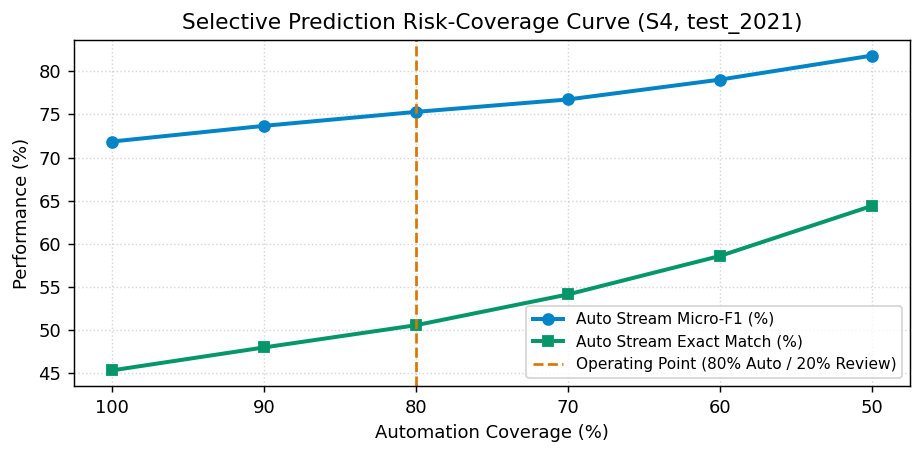

In [6]:
def compute_ece(y_true, y_prob, n_bins=15):
    yt = y_true.reshape(-1)
    yp = y_prob.reshape(-1)
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    ece = 0.0
    for b0, b1 in zip(bins[:-1], bins[1:]):
        mask = (yp >= b0) & (yp < b1 if b1 < 1.0 else yp <= b1)
        if mask.sum() > 0:
            ece += (mask.sum() / len(yt)) * abs(yp[mask].mean() - yt[mask].mean())
    return float(ece)

s3_prob_21 = np.asarray(runs["S3"][1]["test_2021"]["y_probs"], dtype=float)
ece_s3 = compute_ece(y_true_21, s3_prob_21)
ece_s4 = compute_ece(y_true_21, y_prob_21)
print(f"Expected Calibration Error (ECE, test_2021): S3 (BCE) = {ece_s3:.4f} -> S4 (Damped W-BCE) = {ece_s4:.4f} ({ece_s4/ece_s3:.2f}x)")

# Per-class Overconfidence Gap when y_hat = 1
cal_rows = []
for lbl in ["youth_&_student_life", "learning_&_educational", "other_hobbies", "food_&_dining", "celebrity_&_pop_culture", "business_&_entrepreneurs", "film_tv_&_video", "news_&_social_concern", "music", "sports"]:
    i = IDX[lbl]
    pos_pred = y_pred_21[:, i] == 1
    mean_p = float(y_prob_21[pos_pred, i].mean()) * 100
    emp_prec = float(y_true_21[pos_pred, i].mean()) * 100
    cal_rows.append({
        "Topic": SHORT[lbl],
        "n_true": int(y_true_21[:, i].sum()),
        "n_pred": int(pos_pred.sum()),
        "Mean_Pred_Prob_%": round(mean_p, 1),
        "Empirical_Prec_%": round(emp_prec, 1),
        "Overconf_Gap_%": round(mean_p - emp_prec, 1),
    })
print("\n=== Per-Class Overconfidence Gap under Damped W-BCE (test_2021) ===")
display(pd.DataFrame(cal_rows))

# Unseen 2021 Hashtag impact
tag_re = re.compile(r"#([A-Za-z0-9_]+)")
seen_tags = {h.lower() for tx in texts_train for h in tag_re.findall(tx)}
has_tag = np.array([bool(tag_re.findall(tx)) for tx in texts_2021])
has_unseen_tag = np.array([any(h.lower() not in seen_tags for h in tag_re.findall(tx)) for tx in texts_2021])
em_arr = np.all(y_true_21 == y_pred_21, axis=1)
print(f"\nUnseen 2021 #Hashtag EM impact: Unseen-tag EM = {em_arr[has_unseen_tag].mean()*100:.2f}% vs Seen-only-tag EM = {em_arr[has_tag & ~has_unseen_tag].mean()*100:.2f}% (Delta = {(em_arr[has_unseen_tag].mean() - em_arr[has_tag & ~has_unseen_tag].mean())*100:+.2f}%)")

# Selective Prediction Risk-Coverage Curve by margin min_c |p - 0.60|
margins = np.min(np.abs(y_prob_21 - 0.60), axis=1)
high_m = margins >= 0.30
low_m = margins < 0.10
print(f"High-margin (m >= 0.30, {high_m.mean()*100:.1f}%): Micro-F1 = {f1_score(y_true_21[high_m], y_pred_21[high_m], average='micro'):.4f} | EM = {em_arr[high_m].mean()*100:.1f}%")
print(f"Borderline  (m <  0.10, {low_m.mean()*100:.1f}%): captures {fp_cnt[low_m].sum()}/{fp_cnt.sum()} = {fp_cnt[low_m].sum()/fp_cnt.sum()*100:.1f}% of all FP | EM = {em_arr[low_m].mean()*100:.1f}%")

order = np.argsort(-margins)
sel_rows = []
for cov in [1.0, 0.9, 0.8, 0.7, 0.6, 0.5]:
    k = int(round(cov * len(order)))
    auto_idx = order[:k]
    esc_idx = order[k:]
    sel_rows.append({
        "Coverage_%": int(cov * 100),
        "Auto_N": k,
        "Auto_Micro_F1": round(float(f1_score(y_true_21[auto_idx], y_pred_21[auto_idx], average="micro", zero_division=0)), 4),
        "Auto_Macro_F1": round(float(f1_score(y_true_21[auto_idx], y_pred_21[auto_idx], average="macro", zero_division=0)), 4),
        "Auto_EM_%": round(float(em_arr[auto_idx].mean()) * 100, 2),
        "Escalated_EM_%": round(float(em_arr[esc_idx].mean()) * 100, 2) if len(esc_idx) else None,
    })
df_sel = pd.DataFrame(sel_rows)
print("\n=== Selective Prediction Risk-Coverage Table (Zero-Retrain on test_2021) ===")
display(df_sel)

# Inline summary chart
fig, ax = plt.subplots(figsize=(7.2, 3.6), dpi=130)
ax.plot(df_sel["Coverage_%"], df_sel["Auto_Micro_F1"] * 100, "o-", color="#0284C7", lw=2.2, label="Auto Stream Micro-F1 (%)")
ax.plot(df_sel["Coverage_%"], df_sel["Auto_EM_%"], "s-", color="#059669", lw=2.2, label="Auto Stream Exact Match (%)")
ax.axvline(80, color="#D97706", ls="--", lw=1.5, label="Operating Point (80% Auto / 20% Review)")
ax.invert_xaxis()
ax.set_xlabel("Automation Coverage (%)")
ax.set_ylabel("Performance (%)")
ax.set_title("Selective Prediction Risk-Coverage Curve (S4, test_2021)")
ax.grid(ls=":", alpha=0.5)
ax.legend(fontsize=8.5)
plt.tight_layout()
plt.show()

---
## 6. Qualitative Case Study Inspector (`test_2021`: Win Cases & Canonical `S4` Failures)

Truy xuất trực tiếp nguyên văn tweet, ground truth và xác suất từng lớp qua các giai đoạn `S0 → S4` cho toàn bộ các ca minh họa trên **Slide 18** (`Idx 608`, `Idx 993`, `Idx 1145`, `Idx 8`) và **Bảng 5.4** trong báo cáo kỹ thuật.

In [7]:
def inspect_case(idx: int, label_note: str):
    gt = [SHORT[LABELS[i]] for i in np.where(y_true_21[idx] == 1)[0]]
    print(f"=== [{label_note}] test_2021 Idx {idx} ===")
    print(f"Tweet : {texts_2021[idx]}")
    print(f"True  : {gt}")
    for tag, _ in STAGES:
        tp = runs[tag][1]["test_2021"]
        yp = np.asarray(tp["y_pred"])[idx]
        pr = np.asarray(tp["y_probs"])[idx]
        pred_lbls = [f"{SHORT[LABELS[i]]} ({pr[i]:.2f})" for i in np.where(yp == 1)[0]]
        fn_lbls = [f"{SHORT[LABELS[i]]} ({pr[i]:.3f})" for i in np.where((y_true_21[idx] == 1) & (yp == 0))[0]]
        print(f"  {tag}: Pred={pred_lbls or ['[]']} | Missed={fn_lbls or ['None']}")
    print()

for cid, note in [
    (608,  "WIN: 3-Label Multi-Topic Recovery S0 -> S4"),
    (172,  "WIN: Empty [] Recovery & FP Control"),
    (993,  "S4 FAILURE 1: Co-occurrence Halo & Entity Shortcut"),
    (1145, "S4 FAILURE 2: Secondary-Label Suppression (sports + news)"),
    (8,    "S4 FAILURE 3: Data Ceiling (Hidden {{URL}})"),
]:
    inspect_case(cid, note)

=== [WIN: 3-Label Multi-Topic Recovery S0 -> S4] test_2021 Idx 608 ===
Tweet : . {@Olivia Rodrigo@} - “drivers license”  Day 1 — 2,029,363  Day 2 — 6,273,988 Day 3 — 10,068,818 Day 4 — 15,167,905 Day 5 — 17,009,697  1st week total so far: 50,549,771 streams.
True  : ['celebrity', 'film_tv', 'music']
  S0: Pred=['diaries (0.71)'] | Missed=['celebrity (0.040)', 'film_tv (0.026)', 'music (0.041)']
  S1: Pred=['diaries (0.57)'] | Missed=['celebrity (0.063)', 'film_tv (0.010)', 'music (0.003)']
  S2: Pred=['celebrity (0.99)', 'music (0.45)'] | Missed=['film_tv (0.349)']
  S3: Pred=['celebrity (0.83)', 'film_tv (0.62)', 'music (0.83)'] | Missed=['None']
  S4: Pred=['celebrity (0.88)', 'film_tv (0.77)', 'music (0.93)'] | Missed=['None']

=== [WIN: Empty [] Recovery & FP Control] test_2021 Idx 172 ===
Tweet : The power of #storytelling (the #mythological structure) {{URL}} via {{USERNAME}} #JosephCampbell
True  : ['arts', 'learning']
  S0: Pred=['[]'] | Missed=['arts (0.255)', 'learning (0.084

---
## 7. Zero-Leakage `validation_2020` Root-Cause Diagnosis (`test_splits_accessed = []`)

Chẩn đoán lỗi độc lập hoàn toàn trên `validation_2020` (`N = 573`, tuyệt đối không đụng `test_2020` hay `test_2021`) để chứng minh sự tồn tại của **Crowd-Annotation Noise / Bayes Ceiling** trong bộ nhãn gốc CardiffNLP (chi tiết đầy đủ tại `docs/validation_error_analysis.md`).

In [8]:
# Strictly validation_2020 only (test_splits_accessed = [])
y_val_true = np.asarray(s4_vp["y_true"], dtype=int)
y_val_prob = np.asarray(s4_vp["y_probs_raw"], dtype=float)
y_val_pred = (y_val_prob >= 0.60).astype(int)

val_fp = int(((y_val_true == 0) & (y_val_pred == 1)).sum())
val_fn = int(((y_val_true == 1) & (y_val_pred == 0)).sum())
val_fail = int(np.any(y_val_true != y_val_pred, axis=1).sum())
print(f"validation_2020 (N={len(y_val_true)}): Failed tweets = {val_fail} ({val_fail/len(y_val_true)*100:.1f}%) | Binary Errors = {val_fp + val_fn} ({val_fp} FP + {val_fn} FN)")

# Concrete Crowd-Annotation Noise examples on validation_2020
print("\n=== Representative Crowd-Annotation Noise / Incomplete Multi-Label Cases (validation_2020) ===")
for vidx, note in [
    (494, "Mislabeled GT: Rick Ross / August Alsina rap track labeled 'sports'"),
    (447, "Mislabeled GT: Odisha Cyclone Fani & Chief Minister labeled 'other_hobbies'"),
    (24,  "Missing Positive GT: Star Citizen / Cloud Imperium Games missing 'gaming'"),
    (298, "Incomplete Multi-Label: COVID-19 university students petition missing 'youth'"),
]:
    gt = [SHORT[LABELS[i]] for i in np.where(y_val_true[vidx] == 1)[0]]
    pr = [f"{SHORT[LABELS[i]]} ({y_val_prob[vidx, i]:.3f})" for i in np.where(y_val_pred[vidx] == 1)[0]]
    print(f"ValIdx {vidx} — {note}")
    print(f"  Tweet: {texts_val[vidx]}")
    print(f"  GT   : {gt}  |  S4 Pred: {pr}\n")

validation_2020 (N=573): Failed tweets = 311 (54.3%) | Binary Errors = 532 (246 FP + 286 FN)

=== Representative Crowd-Annotation Noise / Incomplete Multi-Label Cases (validation_2020) ===
ValIdx 494 — Mislabeled GT: Rick Ross / August Alsina rap track labeled 'sports'
  Tweet: Wayment Rick Ross’ world play in Entanglements got me hypeeeeeeeeee {@August Alsina@} {@Yung Rnzl@}
  GT   : ['sports']  |  S4 Pred: ['celebrity (0.971)', 'music (0.993)']

ValIdx 447 — Mislabeled GT: Odisha Cyclone Fani & Chief Minister labeled 'other_hobbies'
  Tweet: Glad to know our Odisha recovering from to the bad times. Braving Fani  #BandeUtkalaJanani #ListenToTheSea {@CMO Odisha@} {@Naveen Patnaik@}
  GT   : ['hobbies']  |  S4 Pred: ['news (0.978)']

ValIdx 24 — Missing Positive GT: Star Citizen / Cloud Imperium Games missing 'gaming'
  Tweet: New video! 890 Jump cinematic! About a year ago, I came up with the idea of ​​this video, and finally I was able to bring it to life. And I hope you will like it!